# ENGE707 Facial Feature Classification Challenge

## Task 1: Dataset Exploration and Understanding

This notebook explores the official Kaggle training and test datasets before model development. It examines the dataset structure, target classes, class distribution, representative images, image dimensions, corrupted files, duplicate images, and potential data-quality issues.

The labelled data will later be divided into training and validation subsets, while the unlabelled Kaggle test images will be used only to generate the final competition submission.

In [5]:
from pathlib import Path
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image, ImageFile

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

ImageFile.LOAD_TRUNCATED_IMAGES = True

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data" / "raw"
TRAIN_DIR = DATA_DIR / "train" / "train"
TEST_DIR = DATA_DIR / "test" / "test"
LABELS_PATH = DATA_DIR / "train_labels.csv"
SAMPLE_SUBMISSION_PATH = DATA_DIR / "sample_submission.csv"
FIGURES_DIR = PROJECT_ROOT / "outputs" / "figures"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Training directory exists:", TRAIN_DIR.exists())
print("Test directory exists:", TEST_DIR.exists())
print("Labels file exists:", LABELS_PATH.exists())
print("Sample submission exists:", SAMPLE_SUBMISSION_PATH.exists())

Project root: /Users/amanm/Documents/KAGGLE/ENGE707-Facial-Feature-Classification
Training directory exists: True
Test directory exists: True
Labels file exists: True
Sample submission exists: True


In [6]:
train_labels = pd.read_csv(
    LABELS_PATH,
    dtype={"image_id": str})

sample_submission = pd.read_csv(
    SAMPLE_SUBMISSION_PATH,
    dtype={"image_id": str})

print("Training labels shape:", train_labels.shape)
print("Sample submission shape:", sample_submission.shape)

print("\nTraining-label columns:")
print(train_labels.columns.tolist())

print("\nTarget classes:")
print(sorted(train_labels["class"].unique()))

print("\nFirst five training labels:")
display(train_labels.head())

print("\nFirst five sample-submission rows:")
display(sample_submission.head())

Training labels shape: (63660, 2)
Sample submission shape: (29443, 2)

Training-label columns:
['image_id', 'class']

Target classes:
['CatEye', 'CatFace', 'CatMouth', 'CatNose', 'DogEye', 'DogFace', 'DogMouth', 'DogNose']

First five training labels:


,image_id,class
0,00001,DogEye
1,00002,DogMouth
2,00003,DogFace
3,00004,DogNose
4,00005,DogNose



First five sample-submission rows:


,image_id,class
0,1,DogEye
1,2,CatNose
2,3,CatNose
3,4,DogFace
4,5,DogMouth


Class distribution:


,image_count
class,
CatEye,13884
CatFace,6942
CatMouth,6942
CatNose,6942
DogEye,11580
DogFace,5790
DogMouth,5790
DogNose,5790


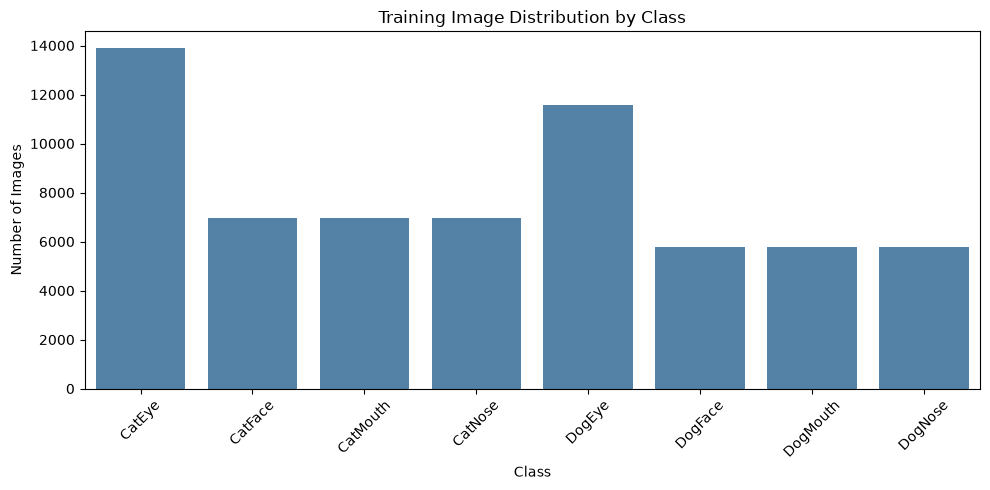

In [7]:
class_counts = (
    train_labels["class"]
    .value_counts()
    .sort_index()
)

print("Class distribution:")
display(class_counts.to_frame(name="image_count"))

plt.figure(figsize=(10, 5))
sns.barplot(x=class_counts.index, y=class_counts.values, color="steelblue")
plt.title("Training Image Distribution by Class")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(FIGURES_DIR / "class_distribution.png", dpi=300)
plt.show()

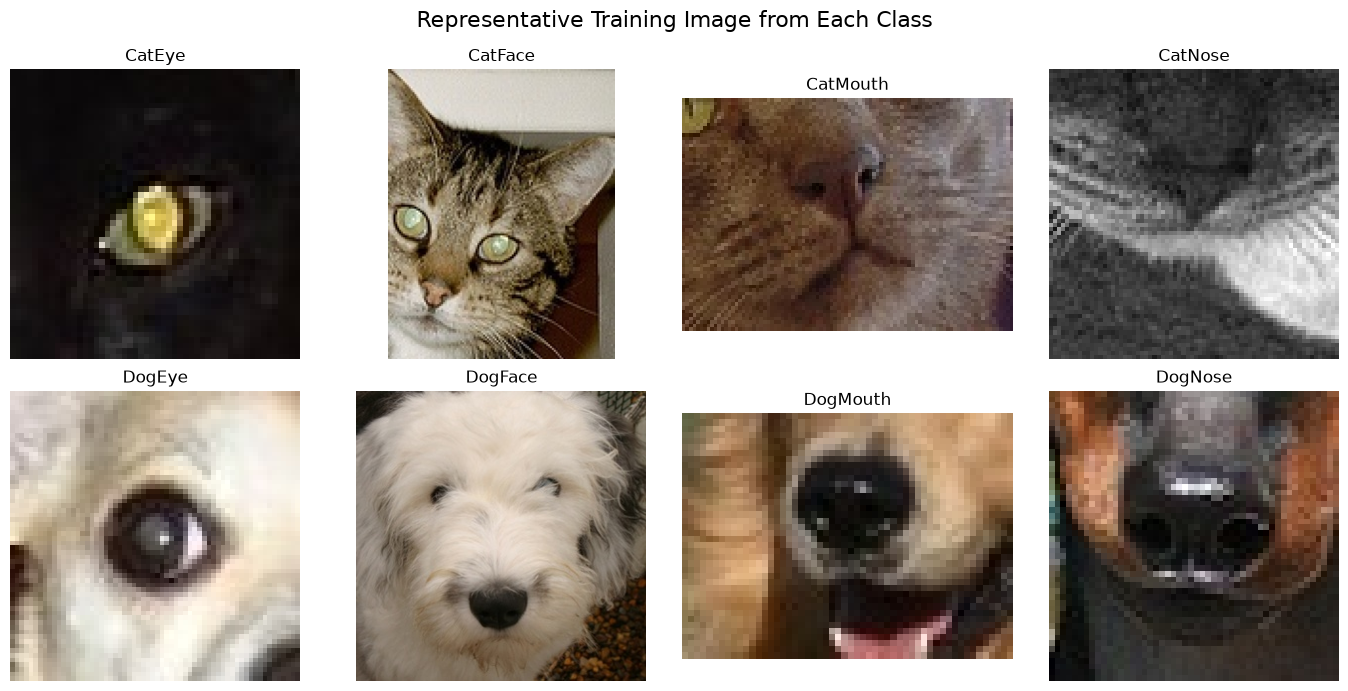

In [8]:
classes = sorted(train_labels["class"].unique())

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
axes = axes.flatten()

for ax, class_name in zip(axes, classes):
    sample_row = (
        train_labels[train_labels["class"] == class_name]
        .sample(1, random_state=42)
        .iloc[0]
    )

    image_path = TRAIN_DIR / f"{sample_row['image_id']}.jpg"
    image = Image.open(image_path).convert("RGB")

    ax.imshow(image)
    ax.set_title(class_name)
    ax.axis("off")

plt.suptitle("Representative Training Image from Each Class", fontsize=16)
plt.tight_layout()

plt.savefig(FIGURES_DIR / "class_samples.png", dpi=300, bbox_inches="tight")
plt.show()

In [9]:
from collections import Counter
from tqdm.auto import tqdm

def inspect_images(folder, label):
    image_files = sorted(folder.glob("*.jpg"))
    dimensions = []
    corrupted = []

    for image_path in tqdm(image_files, desc=f"Checking {label} images"):
        try:
            with Image.open(image_path) as image:
                dimensions.append(image.size)
                image.verify()
        except Exception:
            corrupted.append(image_path.name)

    return image_files, dimensions, corrupted

train_files, train_dimensions, corrupted_train = inspect_images(
    TRAIN_DIR, "training"
)
test_files, test_dimensions, corrupted_test = inspect_images(
    TEST_DIR, "test"
)

train_size_counts = Counter(train_dimensions)
test_size_counts = Counter(test_dimensions)

print("Training image files:", len(train_files))
print("Test image files:", len(test_files))
print("Corrupted training images:", len(corrupted_train))
print("Corrupted test images:", len(corrupted_test))
print("Unique training dimensions:", len(train_size_counts))
print("Unique test dimensions:", len(test_size_counts))

print("\nMost common training dimensions:")
print(train_size_counts.most_common(10))

print("\nMost common test dimensions:")
print(test_size_counts.most_common(10))


Checking training images:   0%|          | 0/63660 [00:00<?, ?it/s]

Checking test images:   0%|          | 0/29443 [00:00<?, ?it/s]

Training image files: 63660
Test image files: 29443
Corrupted training images: 0
Corrupted test images: 0
Unique training dimensions: 7861
Unique test dimensions: 7786

Most common training dimensions:
[((40, 40), 1062), ((48, 48), 1051), ((42, 42), 1050), ((38, 38), 1002), ((44, 44), 1002), ((46, 46), 985), ((34, 34), 978), ((36, 36), 963), ((54, 54), 952), ((52, 52), 928)]

Most common test dimensions:
[((40, 40), 503), ((50, 50), 402), ((80, 80), 370), ((30, 30), 349), ((60, 60), 343), ((70, 70), 260), ((64, 64), 185), ((50, 40), 177), ((90, 90), 162), ((62, 62), 162)]


In [10]:
train_ids = train_labels["image_id"].astype(str)
submission_ids = sample_submission["image_id"].astype(str)

train_file_ids = {path.stem for path in train_files}
test_file_ids = {str(int(path.stem)) for path in test_files}

missing_train_labels = train_labels["class"].isna().sum()
duplicate_train_ids = train_ids.duplicated().sum()
duplicate_submission_ids = submission_ids.duplicated().sum()

labels_without_images = set(train_ids) - train_file_ids
images_without_labels = train_file_ids - set(train_ids)

submission_without_images = set(submission_ids) - test_file_ids
test_images_without_submission = test_file_ids - set(submission_ids)

print("Missing training labels:", missing_train_labels)
print("Duplicate training IDs:", duplicate_train_ids)
print("Duplicate submission IDs:", duplicate_submission_ids)

print("Labels without training images:", len(labels_without_images))
print("Training images without labels:", len(images_without_labels))
print("Submission IDs without test images:", len(submission_without_images))
print("Test images without submission IDs:", len(test_images_without_submission))

Missing training labels: 0
Duplicate training IDs: 0
Duplicate submission IDs: 0
Labels without training images: 0
Training images without labels: 0
Submission IDs without test images: 0
Test images without submission IDs: 0


In [11]:
import hashlib
from collections import defaultdict

hash_groups = defaultdict(list)

for image_path in tqdm(train_files, desc="Hashing training images"):
    with open(image_path, "rb") as file:
        image_hash = hashlib.sha256(file.read()).hexdigest()

    hash_groups[image_hash].append(image_path.stem)

duplicate_groups = {
    image_hash: image_ids
    for image_hash, image_ids in hash_groups.items()
    if len(image_ids) > 1
}

duplicate_image_count = sum(
    len(image_ids) - 1
    for image_ids in duplicate_groups.values()
)

label_lookup = train_labels.set_index("image_id")["class"].to_dict()

conflicting_groups = []

for image_ids in duplicate_groups.values():
    labels = {label_lookup[image_id] for image_id in image_ids}

    if len(labels) > 1:
        conflicting_groups.append({
            "image_ids": image_ids,
            "labels": sorted(labels)
        })

print("Exact duplicate groups:", len(duplicate_groups))
print("Additional duplicate image files:", duplicate_image_count)
print("Duplicate groups with conflicting labels:", len(conflicting_groups))

print("\nFirst five duplicate groups:")
for image_ids in list(duplicate_groups.values())[:5]:
    print(image_ids, "->", [label_lookup[image_id] for image_id in image_ids])

Hashing training images:   0%|          | 0/63660 [00:00<?, ?it/s]

Exact duplicate groups: 15
Additional duplicate image files: 15
Duplicate groups with conflicting labels: 0

First five duplicate groups:
['00356', '06903'] -> ['CatEye', 'CatEye']
['03365', '42280'] -> ['CatEye', 'CatEye']
['03926', '56008'] -> ['CatEye', 'CatEye']
['04003', '46057'] -> ['DogEye', 'DogEye']
['07219', '12150'] -> ['CatMouth', 'CatMouth']


## Dataset Exploration Summary

The dataset includes 63,660 labelled training images and 29,443 unlabelled test images across eight cat and dog facial-feature classes. The classes are not evenly distributed, as the eye categories contain considerably more images than the face, mouth, and nose categories. Because of this, a stratified training-validation split will be used.

The dataset was generally in good condition. No missing labels, corrupted images, duplicate IDs, or mismatches between the CSV files and image folders were found. However, the images have many different dimensions, so they will need to be resized consistently before training. Fifteen pairs of identical images were also found, although every pair had matching labels. One image from each pair will be excluded before splitting the data to avoid leakage.

The sample images vary in lighting, colour, crop, size, and clarity. Therefore, resizing, normalisation, and suitable data augmentation will be included in the preprocessing pipeline.